# De Tijd Sentiment Scores

This notebook contains the Natural Language Processing for the per industry articles in De Tijd 

NOTE: we didn't do sentiment analysis with textblob since it is outdated

In [2]:
# Import dependencies
import findspark, pyspark
import os
import pandas as pd
import numpy as np
import re
import string
import spacy
from functools import reduce
from pyspark.sql import DataFrame
import umap
import umap.plot
from mpl_toolkits.mplot3d import Axes3D
import random

import matplotlib.pyplot as plt
import seaborn as sns

import pyspark.sql.functions as F
from pyspark.sql.types import ArrayType, DoubleType, NumericType, StringType, StructType, StructField, FloatType
from pyspark.ml.feature import Word2Vec, StandardScaler, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
from pyspark.ml.linalg import Vectors, VectorUDT

from pyspark.ml import Pipeline

from textblob import TextBlob

from string import punctuation
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from pyspark.sql import SparkSession, Window
from pyspark import SparkConf
from pyspark.sql.functions import col, rand, when, avg, count, round
import psutil, os, time, pandas as pd, matplotlib.pyplot as plt

from sklearn.manifold import TSNE 
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity

# Initialize findspark to locate Spark installation
#findspark.init('/Users/douwepauwels/sources/spark')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compil

In [3]:
# Create Spark1 session: we use the following configurations:

# - master("local[*]"): Run Spark locally with as many worker threads as logical cores on your machine.
# - config("spark.driver.memory", "1g"): Allocate 1 GB of memory to the Spark driver.
# - config("spark.executor.memory", "2g"): Allocate 2 GB of memory to each Spark executor.
# - appName("IntroToSpark"): Name the Spark application "IntroToSpark".

spark = SparkSession.builder \
    .master("local[*]") \
    .config("spark.driver.memory", "2g") \
    .config("spark.executor.memory", "4g") \
    .config("spark.ui.port", "4040") \
    .appName("IntroToSpark1") \
    .getOrCreate()

sc1 = spark.sparkContext  # To access SparkContext if needed
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/14 19:44:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [4]:
# -----------------------
# REMOVE TEXT FUNCTIONS
# -----------------------

# define punctuation and stopwords
PUNCTUATION = [char for char in punctuation if char not in ["!", "@", "#", "%", "(", ")"]] # ADD more if needed
STOPWORDS = stopwords.words("english")
CONTEXT_WORDS = ['gold', 'silver', 'copper']

# define function to remove punctuation
def remove_punct(text):
    # remove punctuation
    text = "".join([char for char in text if char not in PUNCTUATION])
    return(text)

# define function to remove stopwords
def remove_stopwords(text):
    text = " ".join([word for word in text.split(" ") if word not in STOPWORDS])
    return(text)

# define function to remove context words
def remove_context_words(text):
    text = " ".join([word for word in text.split(" ") if word not in CONTEXT_WORDS])
    return(text)


# define function to remove urls
def remove_urls(text):
    url_pattern = r'http\S+|www\.\S+'
    return re.sub(url_pattern, '', text)

# define function to remove numbers 
def remove_numbers(text):
    pattern = r'\b\d+(\.\d+)?([kKmMbB])?\b|\$\d+(\.\d+)?'
    return re.sub(pattern, '', text)

# define function to remove stock tickers 
def remove_tickers(text):
    # tickers like AEM.TO, AAA.V, XYZ.CD
    ticker_pattern = r'\b[A-Z]{2,5}\.[A-Z]{1,3}\b'
    # tickers like AAPL, TSLA
    plain_ticker_pattern = r'\b[A-Z]{2,5}\b'
    # cashtags like $AAPL
    cashtag_pattern = r'\$[A-Za-z]{2,5}'

    text = re.sub(ticker_pattern, '', text)
    text = re.sub(cashtag_pattern, '', text)
    text = re.sub(plain_ticker_pattern, '', text)
    return text

# define function to remove unnecassary whitespaces
def clean_whitespace(text):
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# define function to lemmatize text
nlp = spacy.load("en_core_web_lg")

def spacy_lemmatize(text):
    doc = nlp(text)
    return " ".join([token.lemma_ for token in doc])

#...
# 

# -----------------------
# Removing part of the text: general company info after each article, licence info, etc.
# -----------------------
# INIT DICTIONARY WITH REGEXES
regex_dict = {
    'ARG.TO': [
        r'About Amerigo.*',  # remove "About Amerigo" and everything after (same line unless DOTALL)
        r'^.*?\([“"]Amerigo[”"]\s+or\s+the\s+[“"]Company[”"]\)',  # remove everything before + that parenthetical (+ optional comma)
        r'Amerigo'
    ],
    'AYA.TO': [
        r'^.*?\([“"]Aya[”"]\s+or\s+the\s+[“"]Corporation[”"]\)',
        r'^.*?\(\s*«\s*Aya\s*»\s+ou\s+la\s+«\s*Société\s*»\s*\)', 
        r'(?s)À propos d’Aya Or & Argent Inc\..*', 
        r'(?s)About Aya Gold & Silver Inc\..*',
        r'Aya'
    ],
    'CG.TO': [
        r'',

    ],
    'CGC.V': [
        r'',
    ],
    'CKG.V': [
        r'',
    ],
    'DMX.V': [
        r'',
    ],
    'DV.V': [
        r'',
    ],  
    'EDG.V': [
        r'',
    ],
    'ELO.TO': [
        r'',
    ],
    'EQX': [
        r'',
    ],
    'ESK.V': [
        r'',
    ],
    'FAS.V': [
        r'',
    ],
    'FDY.TO': [
        r'',
    ],  
    'FINX.V': [
        r'',
    ],
    'FNM.V': [
        r'',
    ],
    'FOM.TO': [
        r'',
    ],
    'FURY.TO': [
        r'',
    ],
    'FVL.TO': [
        r'',
    ],
    'FWZ.V': [
        r'',
    ]
}

# Function
def remove_redundant_text_udf_factory(ticker):
    def _remove(text):
        regexes = regex_dict[ticker]
        for regex in regexes:
            text = re.sub(regex, '', text, flags=re.DOTALL)
        return text
    return F.udf(_remove, StringType())


# -----------------------
# DON'T forget to register them as a udf 
# -----------------------
remove_punct_udf = F.udf(remove_punct, StringType())
remove_stopwords_udf = F.udf(remove_stopwords, StringType())
remove_context_words_udf = F.udf(remove_context_words, StringType())
remove_urls_udf = F.udf(remove_urls, StringType())
remove_numbers_udf = F.udf(remove_numbers, StringType())
remove_tickers_udf = F.udf(remove_tickers, StringType())
clean_whitespace_udf = F.udf(clean_whitespace, StringType())
spacy_lemmatize_udf = F.udf(spacy_lemmatize, StringType())

## Load in the Data

In [5]:
from pyspark.sql import SparkSession
import glob
from pyspark.sql import functions as F
from pyspark.sql.types import StructType

# Initialize Spark session
spark = SparkSession.builder \
    .appName("DETIJD_JSON_Extractor") \
    .getOrCreate()

#Extract all json files
def extract_all_json_with_category(data_dir):
    '''
    Extract all JSONL files from the De_tijd_data folder and add a category column based on filename
    
    data_dir: directory containing JSONL files
    '''
    all_dfs = []
    
    files = glob.glob(f'{data_dir}/*.jsonl')
    
    print(f"Looking for JSONL files in: {data_dir}")
    print(f"Found {len(files)} files: {files}")
    
    for file_path in files:
        try:
            filename = file_path.split('/')[-1]
            
            # REMOVE DETIJD_ PREFIX from category name
            category_name = filename.replace('DETIJD_', '').replace('.jsonl', '')
            
            print(f"\nProcessing: {filename}")
            print(f"Category: {category_name}")
            
            df = spark.read.option("multiLine", 'false').json(file_path)
            
            print(f"Schema for {filename}:")
            df.printSchema()
            
            row_count = df.count()
            print(f"Number of articles: {row_count}")
            
            if row_count > 0:
                print("Sample data:")
                df.show(2, truncate=50)
            
            # Add category column (without DETIJD_ prefix)
            df = df.withColumn('category', F.lit(category_name))
            
            # Standardize column names
            date_columns = ['date', 'published', 'pubDate']
            for date_col in date_columns:
                if date_col in df.columns:
                    df = df.withColumnRenamed(date_col, 'date')
                    break
            
            content_columns = ['content', 'text', 'body']
            for content_col in content_columns:
                if content_col in df.columns:
                    df = df.withColumnRenamed(content_col, 'content')
                    break
            
            title_columns = ['title', 'headline']
            for title_col in title_columns:
                if title_col in df.columns:
                    df = df.withColumnRenamed(title_col, 'title')
                    break
            
            # Ensure we have required columns
            required_columns = ['date', 'content', 'title', 'url']
            for col_name in required_columns:
                if col_name not in df.columns:
                    df = df.withColumn(col_name, F.lit(None))
            
            df = df.withColumn('ticker', F.lit(None))
            
            # REMOVE source_file from select - only keep necessary columns
            df = df.select(['date', 'content', 'ticker', 'title', 'url', 'category'])
            
            all_dfs.append(df)
            print(f"✓ Successfully processed {filename}")
            
        except Exception as e:
            print(f"✗ Error reading {file_path}: {str(e)}")
            import traceback
            traceback.print_exc()
    
    # Combine all DataFrames
    if all_dfs:
        print("\n" + "="*80)
        print("COMBINING ALL DATAFRAMES")
        print("="*80)
        
        combined_df = all_dfs[0]
        for df in all_dfs[1:]:
            combined_df = combined_df.unionByName(df, allowMissingColumns=True)
        
        print("\nFinal combined DataFrame schema:")
        combined_df.printSchema()
        
        total_rows = combined_df.count()
        print(f"\n✅ SUCCESS! Total articles processed: {total_rows}")
        
        print("\n📊 Distribution by category (without DETIJD_ prefix):")
        combined_df.groupBy('category').count().orderBy('count', ascending=False).show()
        
        # FIX: Removed source_file from this select statement
        print("\n📋 Sample of final data:")
        combined_df.select('category', 'title', 'date').show(10, truncate=30)
        
        return combined_df
    else:
        print("❌ No files were processed successfully.")
        return spark.createDataFrame([], schema=StructType([]))

# Run the extraction
data_dir = '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data'

print("="*80)
print("STARTING JSON EXTRACTION FROM DETIJD DATA FOLDER")
print("="*80)

detijd_data = extract_all_json_with_category(data_dir)

# If you want to save the result
if detijd_data.count() > 0:
    print("\n Would you like to save the combined data?")
    # Uncomment to save:
    # output_path = '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/combined_detijd_data.parquet'
    # detijd_data.write.mode('overwrite').parquet(output_path)
    # print(f"Data saved to: {output_path}")

# Show final summary
print("\n" + "="*80)
print("EXTRACTION COMPLETE")
print("="*80)
print(f"Total categories processed: {detijd_data.select('category').distinct().count()}")
print(f"Total articles: {detijd_data.count()}")

# If you want to see the actual content of some articles
print("\n Sample article content (first 3 articles):")
detijd_data.select('category', 'title', F.substring('content', 1, 100).alias('content_preview')).show(3, truncate=False)

25/12/14 19:44:44 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


STARTING JSON EXTRACTION FROM DETIJD DATA FOLDER
Looking for JSONL files in: /Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data
Found 11 files: ['/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Koper_bedrijven.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Platina.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Zilver.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Palladium.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Platinum.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_goud_bedrijven.jsonl', '/Users/vincenzov

## Category Mapping (several functions)

In [6]:
from pyspark.sql import functions as F

# Define category mapping (necessary for differen scraped file) 
def map_category_after_extraction(df):
    """
    Map original categories to standardized names after extraction
    """
    # Define the mapping dictionary
    category_mapping = {

        # Gold-related categories
        'goud_bedrijven': 'Gold',
        'Goud': 'Gold',
        'goud': 'Gold',
        
        # Copper-related categories
        'koper': 'Copper',
        'Koper_bedrijven': 'Copper',
        
        # Silver-related categories
        'Zilver': 'Silver',
        'zilver': 'Silver',
        'Zilver_bedrijven': 'Silver',
        
        # Precious Metals categories (map to Other Precious Metals & Mining)
        'Edelmetalen': 'Other Precious Metals & Mining',  # Means "Precious Metals"
        'Platina': 'Other Precious Metals & Mining',
        'platina': 'Other Precious Metals & Mining',
        'Platinum': 'Other Precious Metals & Mining',
        'Palladium': 'Other Precious Metals & Mining',
        
        # Industrial Metals (map to Other Industrial Metals & Mining)
        'Industriële_Metalen': 'Other Industrial Metals & Mining', 

        #If any new scraped files are created, their mapping can be added here 

    }
    
    # Create a when() expression for mapping
    mapping_expr = F.coalesce(*[
        F.when(F.col('category') == orig_cat, F.lit(new_cat))
        for orig_cat, new_cat in category_mapping.items()
    ], F.col('category'))  # Keep original if no mapping found
    
    # Apply the mapping
    df_mapped = df.withColumn('category', mapping_expr)    
    return df_mapped

# Usage after extraction
detijd_data = extract_all_json_with_category(data_dir)

# Apply category mapping
detijd_data_mapped = map_category_after_extraction(detijd_data)

# Show the results
print("Original categories vs Mapped categories:")
detijd_data.select('category').distinct().show(truncate=False)
detijd_data_mapped.select('category').distinct().show(truncate=False)

# Show distribution after mapping
print("\n📊 Distribution by mapped category:")
detijd_data_mapped.groupBy('category').count().orderBy('count', ascending=False).show()

# Alternative approach: if you want to handle case-insensitive matching
def map_category_case_insensitive(df):
    """
    Map categories with case-insensitive matching
    """
    from pyspark.sql import functions as F
    
    # Define the mapping - use lower case for matching
    category_mapping = {
        
        # Gold-related categories
        'goud_bedrijven': 'Gold',
        'Goud': 'Gold',
        'goud': 'Gold',
        
        # Copper-related categories
        'koper': 'Copper',
        'Koper_bedrijven': 'Copper',
        
        # Silver-related categories
        'Zilver': 'Silver',
        'zilver': 'Silver',
        'Zilver_bedrijven': 'Silver',
        
        # Precious Metals categories (map to Other Precious Metals & Mining)
        'Edelmetalen': 'Other Precious Metals & Mining',  # Means "Precious Metals"
        'Platina': 'Other Precious Metals & Mining',
        'platina': 'Other Precious Metals & Mining',
        'Platinum': 'Other Precious Metals & Mining',
        'Palladium': 'Other Precious Metals & Mining',
        
        # Industrial Metals (map to Other Industrial Metals & Mining)
        'Industriële_Metalen': 'Other Industrial Metals & Mining', 
    }
    
    # Convert category to lower case for case-insensitive matching
    df_lower = df.withColumn('category_lower', F.lower(F.col('category')))
    
    # Create mapping expression
    mapping_expr = F.coalesce(*[
        F.when(F.col('category_lower') == orig_cat, F.lit(new_cat))
        for orig_cat, new_cat in category_mapping.items()
    ], F.lit('Other Industrial Metals & Mining'))  # Default to this if no match
    
    # Apply mapping and drop temporary column
    df_mapped = df_lower.withColumn('category', mapping_expr).drop('category_lower')
    
    return df_mapped

# Or if you want a more comprehensive mapping that covers all your desired categories:
def comprehensive_category_mapping(df):
    """
    Comprehensive mapping to all 6 desired categories
    """
    # First map known specific categories
    specific_mapping = {

        # Gold-related categories
        'goud_bedrijven': 'Gold',
        'Goud': 'Gold',
        'goud': 'Gold',
        
        # Copper-related categories
        'koper': 'Copper',
        'Koper_bedrijven': 'Copper',
        
        # Silver-related categories
        'Zilver': 'Silver',
        'zilver': 'Silver',
        'Zilver_bedrijven': 'Silver',
        
        # Precious Metals categories (map to Other Precious Metals & Mining)
        'Edelmetalen': 'Other Precious Metals & Mining',  # Means "Precious Metals"
        'Platina': 'Other Precious Metals & Mining',
        'platina': 'Other Precious Metals & Mining',
        'Platinum': 'Other Precious Metals & Mining',
        'Palladium': 'Other Precious Metals & Mining',
        
        # Industrial Metals (map to Other Industrial Metals & Mining)
        'Industriële_Metalen': 'Other Industrial Metals & Mining', 
    }
    
    # Apply specific mapping first
    mapping_expr = F.coalesce(*[
        F.when(F.col('category') == orig_cat, F.lit(new_cat))
        for orig_cat, new_cat in specific_mapping.items()
    ], F.col('category'))
    
    df = df.withColumn('category', mapping_expr)
    
    # Now handle broader categorization for any remaining categories
    # This assumes any category not already mapped needs to be categorized
    
    # Check what categories we still have
    remaining_categories = [row['category'] for row in df.select('category').distinct().collect()]
    print(f"Categories after specific mapping: {remaining_categories}")
    
    # For demonstration, if you have other categories you want to map:
    # You could add logic here to map based on keywords in the category name
    
    return df

# Run the mapping
detijd_data_mapped = comprehensive_category_mapping(detijd_data)

# Show final categories
print("\n🎯 FINAL CATEGORIES:")
detijd_data_mapped.select('category').distinct().show(truncate=False)

# Optional: If you want to ensure all articles are in the 5 specified categories:
def enforce_final_categories(df):
    """
    Ensure all articles are in one of the 5 specified categories
    """
    final_categories = ['Gold', 'Copper', 'Silver', 'Other Precious Metals & Mining', 
                       'Other Industrial Metals & Mining']
    
    # Create a column to check if category is valid
    df = df.withColumn(
        'is_valid_category',
        F.col('category').isin(final_categories)
    )
    
    # Show invalid categories (for debugging)
    invalid_cats = df.filter(~F.col('is_valid_category')).select('category').distinct().collect()
    if invalid_cats:
        print(f"\n  Found categories not in final list: {[row['category'] for row in invalid_cats]}")
        print("Consider adding mapping for these categories")
    
    # Drop the temporary column
    df = df.drop('is_valid_category')
    
    return df

# Apply final validation
detijd_data_final = enforce_final_categories(detijd_data_mapped)

Looking for JSONL files in: /Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data
Found 11 files: ['/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Koper_bedrijven.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Platina.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Zilver.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Palladium.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_Platinum.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Data/Textual_data/De_tijd_data/DETIJD_goud_bedrijven.jsonl', '/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_

In [7]:
#Final check if the categories were properly added 
detijd_data_final.show(2000)

+-----------------+--------------------+------+--------------------+--------------------+--------------------+
|             date|             content|ticker|               title|                 url|            category|
+-----------------+--------------------+------+--------------------+--------------------+--------------------+
| 2025-12-12 18:00|België en de effe...|  NULL|Overleeft Eurocle...|https://www.tijd....|              Copper|
| 2025-11-27 12:19|Sinds de referent...|  NULL|Chinees moederbed...|https://www.tijd....|              Copper|
| 2025-11-24 10:25|De Australische m...|  NULL|Mijnbouwreus BHP ...|https://www.tijd....|              Copper|
| 2025-11-21 16:53|De gevolgen van d...|  NULL|Sancties tegen Ru...|https://www.tijd....|              Copper|
| 2025-11-21 14:57|De beursgenoteerd...|  NULL|Loont het om de i...|https://www.tijd....|              Copper|
| 2025-11-19 19:17|De rol van de Eur...|  NULL|Van leidend naar ...|https://www.tijd....|              Copper|
|

In [8]:
# -----------------------
# Cleaning function for a whole dataframe 
# -----------------------
def clean_df(df):
    cleaned_df = df \
                        .withColumn("content", remove_urls_udf("content")) \
                        .withColumn("title", remove_urls_udf("title")) \
                        .withColumn("content", remove_numbers_udf("content")) \
                        .withColumn("title", remove_numbers_udf("title")) \
                        .withColumn("content", remove_tickers_udf("content")) \
                        .withColumn("title", remove_tickers_udf("title")) \
                        .withColumn("content", F.lower("content")) \
                        .withColumn("title", F.lower("title")) \
                        .withColumn("content", remove_punct_udf("content")) \
                        .withColumn("title", remove_punct_udf("title")) \
                        .withColumn("content", remove_stopwords_udf("content")) \
                        .withColumn("title", remove_stopwords_udf("title")) \
                        .withColumn("content", remove_context_words_udf("content")) \
                        .withColumn("title", remove_context_words_udf("title")) \
                        .withColumn("content", F.regexp_replace("content", "\n", " ")) \
                        .withColumn("title", F.regexp_replace("title", "\n", " ")) \
                        .withColumn("content", clean_whitespace_udf("content")) \
                        .withColumn("title", clean_whitespace_udf("title")) \
                        .withColumn("content_lemma", spacy_lemmatize_udf("content")) \
                        .withColumn("title_lemma", spacy_lemmatize_udf("title")) \
                        .withColumn("title_tokenized", F.split("title", " ")) \
                        .withColumn("content_tokenized", F.split("content", " ")) \
                        .withColumn("num_words_title", F.size("title_tokenized")) \
                        .withColumn("num_words_content", F.size("content_tokenized"))
    
    return cleaned_df

In [9]:
detijd_data_final_cleaned = clean_df(detijd_data_final)
detijd_data_final_cleaned = detijd_data_final_cleaned.drop("ticker")
detijd_data_final_cleaned.show(2495)

+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+
|             date|             content|               title|                 url|            category|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|
+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+
| 2025-12-12 18:00|belgië en de effe...|overleeft eurocle...|https://www.tijd....|              Copper|belgië en de effe...|overleeft eurocle...|[overleeft, euroc...|[belgië, en, de, ...|              9|             1564|
| 2025-11-27 12:19|sinds de referent...|chinees moederbed...|https://www.tijd....|              Copper|sinds de 

In [10]:
from pyspark.sql import functions as F
from pyspark.sql.functions import udf
from pyspark.sql.types import DateType
from pyspark.sql.window import Window
import datetime

# 1. Parse dates in your De Tijd data
def parse_mixed_date(date_str):
    """Parse both ISO format and Dutch date strings"""
    if not date_str or date_str.strip() == "":
        return None
    
    date_str = date_str.strip()
    
    # Try ISO format first: "2025-12-12 18:00" or "2025-12-12"
    try:
        # Extract just the date part (before space)
        iso_date = date_str.split()[0]
        return datetime.datetime.strptime(iso_date, "%Y-%m-%d").date()
    except:
        pass
    
    # Try Dutch format: "02 april 2025"
    try:
        dutch_months = {
            'januari': 1, 'februari': 2, 'maart': 3, 'april': 4,
            'mei': 5, 'juni': 6, 'juli': 7, 'augustus': 8,
            'september': 9, 'oktober': 10, 'november': 11, 'december': 12
        }
        
        # Parse format like "02 april 2025"
        parts = date_str.split()
        if len(parts) == 3:
            day = int(parts[0])
            month_str = parts[1].lower()
            year = int(parts[2])
            
            if month_str in dutch_months:
                month = dutch_months[month_str]
                return datetime.date(year, month, day)
    except:
        pass
    
    return None

# Register UDF
parse_mixed_date_udf = udf(parse_mixed_date, DateType())

# Parse dates in your De Tijd dataframe
detijd_with_parsed_dates = detijd_data_final_cleaned.withColumn(
    "parsed_date",
    parse_mixed_date_udf(F.col("date"))
)

In [11]:
detijd_with_parsed_dates.show(2495)

+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+-----------+
|             date|             content|               title|                 url|            category|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|parsed_date|
+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+-----------+
| 2025-12-12 18:00|belgië en de effe...|overleeft eurocle...|https://www.tijd....|              Copper|belgië en de effe...|overleeft eurocle...|[overleeft, euroc...|[belgië, en, de, ...|              9|             1564| 2025-12-12|
| 2025-11-27 12:19|sinds de referent...|chinees moederbed...|htt

In [12]:
import pyspark.sql.functions as F
from pyspark.sql import SparkSession

#NOTE: Assuming your SparkSession is already active and running.

FILE_PATH = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable.parquet"

print(f"Attempting to read Parquet file from: {FILE_PATH}")

try:
    # Load the biweekly basetable (financial data)
    biweekly_data = spark.read.parquet(FILE_PATH).cache()

    # Get the row count
    row_count = biweekly_data.count()
    
    print(f"\n✅ Successfully loaded biweekly basetable.")
    print(f"Total rows (biweekly periods): {row_count}")
    
    # Show the first 5 rows and the schema for inspection
    print("\n--- Biweekly Basetable (Financial Features) - Showing top 5 rows ---")
    biweekly_data.show(100)
    
    print("\n--- Schema ---")
    biweekly_data.printSchema()

except Exception as e:
    print(f"\n❌ ERROR: Failed to read the Parquet file. Ensure the path is correct and accessible.")
    raise

Attempting to read Parquet file from: /Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable.parquet


25/12/14 19:49:39 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.



✅ Successfully loaded biweekly basetable.
Total rows (biweekly periods): 587

--- Biweekly Basetable (Financial Features) - Showing top 5 rows ---
+------+--------------+---------------+--------------------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+-------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+--------+--------------------+-------------------------+-------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------

In [13]:
import pyspark.sql.functions as F
from pyspark.sql.window import Window

print(" PROBLEM IDENTIFIED: Multiple entries for same biweekly_period!")

# 1. FIRST create the period_lookup table (you're missing this part!)
print("Creating Period Lookup Table...")
period_lookup = biweekly_data.select(
    "biweekly_period", 
    F.to_date(F.col("period_start"), "yyyy-MM-dd").alias("start_date"),
    F.to_date(F.col("period_end"), "yyyy-MM-dd").alias("end_date")
).distinct().cache()

print(f"Period Lookup Table Created with {period_lookup.count()} periods")
period_lookup.show(3)

# Check duplicates
print("\nDuplicate biweekly_period entries:")
duplicate_counts = period_lookup.groupBy("biweekly_period").count().filter(F.col("count") > 1)
duplicate_counts.orderBy(F.desc("count")).show()

print("\nExample of P13 duplicates:")
period_lookup.filter(F.col("biweekly_period") == "P13").orderBy("start_date").show()

# FIX: Create a clean period lookup table
print("\n Creating clean period lookup table (deduplicated)...")

# Take the earliest start_date and latest end_date for each period
clean_period_lookup = period_lookup.groupBy("biweekly_period").agg(
    F.min("start_date").alias("start_date"),
    F.max("end_date").alias("end_date")
).orderBy("biweekly_period")

print(f"Original period_lookup rows: {period_lookup.count()}")
print(f"Clean period_lookup rows: {clean_period_lookup.count()}")

print("\n Clean period lookup table:")
clean_period_lookup.show(10)

# Now use the clean lookup table
print("\n Assigning biweekly_period using CLEAN lookup table...")

detijd_with_periods = detijd_with_parsed_dates.join(
    clean_period_lookup,
    (F.col("parsed_date") >= F.col("start_date")) & 
    (F.col("parsed_date") <= F.col("end_date")),
    "left"
)

# Check results
print("\n RESULTS with clean period lookup:")
print(f"Total articles: {detijd_with_periods.count()}")

# Count matches per article
matches_per_article = detijd_with_periods.groupBy("title", "parsed_date", "category").agg(
    F.count("biweekly_period").alias("num_periods")
)

single_match = matches_per_article.filter(F.col("num_periods") == 1).count()
multi_match = matches_per_article.filter(F.col("num_periods") > 1).count()
no_match = matches_per_article.filter(F.col("num_periods") == 0).count()

print(f"Articles matching 1 period: {single_match}")
print(f"Articles matching >1 period: {multi_match}")
print(f"Articles matching 0 periods: {no_match}")

# Handle articles that match multiple periods
if multi_match > 0:
    print("\n Handling articles matching multiple periods...")
    
    # Add a ranking to choose one period per article
    detijd_with_periods = detijd_with_periods.withColumn(
        "period_length", 
        F.datediff(F.col("end_date"), F.col("start_date"))
    )
    
    # Window to rank periods: prefer shorter periods (more specific)
    window_spec = Window.partitionBy("title", "parsed_date", "category").orderBy("period_length", "biweekly_period")
    
    detijd_with_periods = detijd_with_periods.withColumn("period_rank", F.row_number().over(window_spec)) \
        .filter(F.col("period_rank") == 1) \
        .drop("period_rank", "period_length")

# Final dataframe
detijd_final = detijd_with_periods.drop("start_date", "end_date")

print("\n FINAL RESULT:")
print(f"Articles with biweekly_period assigned: {detijd_final.filter(F.col('biweekly_period').isNotNull()).count()}")

# Show sample (first 10, not 2111 which is too many)
print("\n Sample of final dataframe (first 10 rows):")
detijd_final.select("parsed_date", "biweekly_period", "category", "title").show(10, truncate=30)

print("\n Distribution by biweekly_period:")
detijd_final.groupBy("biweekly_period").count().orderBy("biweekly_period").show(truncate=False)

# Show articles without periods
null_periods = detijd_final.filter(F.col("biweekly_period").isNull()).count()
print(f"\n Articles without biweekly_period (outside date range): {null_periods}")

if null_periods > 0:
    print("\n Sample of articles without biweekly_period:")
    detijd_final.filter(F.col("biweekly_period").isNull()) \
        .select("parsed_date", "category", "title") \
        .orderBy("parsed_date", descending=True) \
        .show(303, truncate=30)

# Clean up
period_lookup.unpersist()

# Return final dataframe
detijd_final

 PROBLEM IDENTIFIED: Multiple entries for same biweekly_period!
Creating Period Lookup Table...
Period Lookup Table Created with 73 periods
+---------------+----------+----------+
|biweekly_period|start_date|  end_date|
+---------------+----------+----------+
|            P19|2024-10-07|2024-10-18|
|            P13|2024-07-16|2024-07-26|
|            P18|2024-09-23|2024-10-04|
+---------------+----------+----------+
only showing top 3 rows

Duplicate biweekly_period entries:
+---------------+-----+
|biweekly_period|count|
+---------------+-----+
|            P13|    5|
|            P19|    4|
|            P45|    3|
|            P35|    3|
|            P23|    3|
|             P0|    2|
|            P26|    2|
|            P38|    2|
|            P37|    2|
|             P7|    2|
|            P33|    2|
|            P27|    2|
|            P36|    2|
|            P17|    2|
|            P32|    2|
|            P22|    2|
|            P42|    2|
|            P21|    2|
|            P43

Articles matching 1 period: 1261
Articles matching >1 period: 417
Articles matching 0 periods: 303

 Handling articles matching multiple periods...

 FINAL RESULT:
Articles with biweekly_period assigned: 1678

 Sample of final dataframe (first 10 rows):


+-----------+---------------+--------+-----+
|parsed_date|biweekly_period|category|title|
+-----------+---------------+--------+-----+
|       NULL|           NULL|    Gold|     |
| 2024-01-05|           NULL|    Gold|     |
| 2024-03-06|             P3|    Gold|     |
| 2024-04-09|             P6|  Copper|     |
| 2024-04-09|             P6|    Gold|     |
| 2024-05-15|             P8|    Gold|     |
| 2024-05-29|             P9|    Gold|     |
| 2024-10-08|            P19|    Gold|     |
| 2024-11-13|            P21|    Gold|     |
| 2025-02-12|            P28|    Gold|     |
+-----------+---------------+--------+-----+
only showing top 10 rows

 Distribution by biweekly_period:
+---------------+-----+
|biweekly_period|count|
+---------------+-----+
|NULL           |303  |
|P0             |38   |
|P1             |30   |
|P10            |19   |
|P11            |27   |
|P12            |12   |
|P13            |43   |
|P14            |39   |
|P15            |33   |
|P16            |34   

DataFrame[date: string, content: string, title: string, url: string, category: string, content_lemma: string, title_lemma: string, title_tokenized: array<string>, content_tokenized: array<string>, num_words_title: int, num_words_content: int, parsed_date: date, biweekly_period: string]

In [14]:
detijd_final.show(100)

+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+-----------+---------------+
|             date|             content|               title|                 url|            category|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|parsed_date|biweekly_period|
+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+-----------+---------------+
| 2024-04-09 07:01|de een dagelijkse...|                    |https://www.tijd....|              Copper|de een dagelijkse...|                    |                  []|[de, een, dagelij...|              1|               35| 2024-04-09|             P6|


In [15]:
import pyspark.sql.functions as F

# Count unique category + biweekly_period combinations
unique_combinations = detijd_final.select("category", "biweekly_period").distinct()

print(f" UNIQUE CATEGORY-PERIOD COMBINATIONS:")
print(f"Total unique combinations: {unique_combinations.count()}")

# Show all unique combinations
print("\n All unique combinations:")
unique_combinations.orderBy("biweekly_period", "category").show(truncate=False)

# Count per period
print("\n Unique categories per biweekly_period:")
category_counts = detijd_final.groupBy("biweekly_period").agg(
    F.countDistinct("category").alias("unique_categories")
).orderBy("biweekly_period")

category_counts.show(truncate=False)

# Count per category
print("\n Unique periods per category:")
period_counts = detijd_final.groupBy("category").agg(
    F.countDistinct("biweekly_period").alias("unique_periods")
).orderBy("category")

period_counts.show(truncate=False)

# Create a pivot table to see the complete distribution
print("\n COMPLETE DISTRIBUTION TABLE:")
pivot_table = detijd_final.groupBy("biweekly_period").pivot("category").count().fillna(0)

# Order by period
pivot_table = pivot_table.orderBy("biweekly_period")

# Show the pivot table
pivot_table.show(truncate=False)

# Summary statistics
print("\n SUMMARY STATISTICS:")
total_articles = detijd_final.count()
articles_with_period = detijd_final.filter(F.col("biweekly_period").isNotNull()).count()

print(f"Total articles: {total_articles}")
print(f"Articles with period assigned: {articles_with_period}")
print(f"Unique categories: {detijd_final.select('category').distinct().count()}")
print(f"Unique periods: {detijd_final.select('biweekly_period').filter(F.col('biweekly_period').isNotNull()).distinct().count()}")
print(f"Unique category-period combinations: {unique_combinations.count()}")

 UNIQUE CATEGORY-PERIOD COMBINATIONS:
Total unique combinations: 202

 All unique combinations:


+--------------------------------+---------------+
|category                        |biweekly_period|
+--------------------------------+---------------+
|Copper                          |NULL           |
|Gold                            |NULL           |
|Other Industrial Metals & Mining|NULL           |
|Other Precious Metals & Mining  |NULL           |
|Silver                          |NULL           |
|Copper                          |P0             |
|Gold                            |P0             |
|Other Industrial Metals & Mining|P0             |
|Other Precious Metals & Mining  |P0             |
|Silver                          |P0             |
|Copper                          |P1             |
|Gold                            |P1             |
|Other Industrial Metals & Mining|P1             |
|Silver                          |P1             |
|Copper                          |P10            |
|Gold                            |P10            |
|Copper                        

## Sentiment analysis using TextBlob

functions to retrieve the sentiment scores

In [16]:
from pyspark.sql.functions import udf
from pyspark.sql.types import DoubleType
from textblob import TextBlob

# -----------------------
# POLARITY AND SUBJECTIVITY FUNCTIONS
# -----------------------
def get_polarity(row):
    if row and isinstance(row, str) and len(row.strip()) > 0:
        textBlob_review = TextBlob(row)
        return float(textBlob_review.sentiment[0])
    return 0.0

def get_subjectivity(row):
    if row and isinstance(row, str) and len(row.strip()) > 0:
        textBlob_review = TextBlob(row)
        return float(textBlob_review.sentiment[1])
    return 0.0

def main_textBlob(list_dfs):
    # CREATE UDFs INSIDE THE FUNCTION to avoid conflicts
    get_polarity_udf = udf(get_polarity, DoubleType())
    get_subjectivity_udf = udf(get_subjectivity, DoubleType())
    
    dfs_with_sentiment = []

    for df in list_dfs:
        df_with_sentiment = df.withColumn("polarity_title", get_polarity_udf(F.col("title_lemma"))) \
                              .withColumn("polarity_content", get_polarity_udf(F.col("content_lemma"))) \
                              .withColumn("subjectivity_title", get_subjectivity_udf(F.col("title_lemma"))) \
                              .withColumn("subjectivity_content", get_subjectivity_udf(F.col("content_lemma"))) \
                              .filter("num_words_title > 0 OR num_words_content > 0") \
                              .drop("url") \
                              .cache()
                            
        dfs_with_sentiment.append(df_with_sentiment)
        
    return dfs_with_sentiment


In [17]:
# Test it
if __name__ == "__main__":
    # Make sure detijd_final is a list (wrap it if it's a single DataFrame)
    if not isinstance(detijd_final, list):
        detijd_final = [detijd_final]
    
    result = main_textBlob(detijd_final)
    print(f"✅ Success! Processed {len(result)} DataFrames")
    
    # Get the first (or only) result
    detijd_with_sentiment = result[0]
    print(f"Rows with sentiment: {detijd_with_sentiment.count()}")
    
    # Show sample
    detijd_with_sentiment.select("title", "polarity_title", "subjectivity_title").show(5, truncate=30)

✅ Success! Processed 1 DataFrames


Rows with sentiment: 1981
+------------------------------+--------------+------------------+
|                         title|polarity_title|subjectivity_title|
+------------------------------+--------------+------------------+
|beursfavorieten voor tweede...|           0.6|               0.6|
|                 bitcoinkoorts|           0.0|               0.0|
|canadese mijnbouwer trilogy...|           0.0|               0.0|
|              de betere bazaar|           0.0|               0.0|
|goudprijs tikt nieuwe recor...|           0.0|               0.0|
+------------------------------+--------------+------------------+
only showing top 5 rows


In [18]:
detijd_with_sentiment.show()
dfs = detijd_with_sentiment

+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+-----------+---------------+--------------+--------------------+------------------+--------------------+
|             date|             content|               title|            category|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|parsed_date|biweekly_period|polarity_title|    polarity_content|subjectivity_title|subjectivity_content|
+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+-----------+---------------+--------------+--------------------+------------------+--------------------+
| 2025-06-20 17:45|de zomer doet u h...|beursfavorieten v...|              Silver|de 

## Vector Embeddings using FinBERT

In [19]:
#To install torch with cuda support, follow instructions at https://pytorch.org/get-started/locally/. This will ensure that the model runs on GPU if available.
import torch

from pyspark.ml.functions import array_to_vector
from transformers import AutoTokenizer, AutoModel

Function list for embedding the text

In [20]:
# -----------------------
# INIT MODEL AND TOKENIZER
# -----------------------
MODEL_NAME = "ProsusAI/finbert"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

_tokenizer = None
_model = None

def get_model_and_tokenizer():
    global _tokenizer, _model
    if _tokenizer is None or _model is None:
        _tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
        _model = AutoModel.from_pretrained(MODEL_NAME)
        _model.to(device)
        _model.eval()
    return _tokenizer, _model


# -----------------------
# EMBEDDING TEXT
# -----------------------
def get_embeddings(text):
    if text is None or text == "":
        return None
    
    tokenizer, model = get_model_and_tokenizer()
    
    # Tokenize the input text
    inputs = tokenizer(text, 
                     padding=True, 
                     truncation=True, 
                     max_length=512,
                     return_tensors="pt")
    
    # Move inputs to device
    inputs = {key: val.to(device) for key, val in inputs.items()}
    
    # Generate embeddings without gradient computation
    with torch.no_grad():
        outputs = model(**inputs)

    # Mean pooling - take attention mask into account for correct averaging so we don't include padding tokens
    attention_mask = inputs['attention_mask']
    token_embeddings = outputs.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    embeddings = torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)
    
    # Convert to numpy and then to list
    embedding_list = embeddings.cpu().numpy()[0].tolist()
    
    return embedding_list

# Register the function as a UDF
get_embeddings_udf = F.udf(get_embeddings, ArrayType(DoubleType()))

# -----------------------
# MAIN 
# -----------------------
def main_finBERT(list_dfs):

    dfs_with_embeddings = [] 

    for df in list_dfs:

        # APPLY EMBEDDING
        df_with_embeddings = df.withColumn(
            "finbert_embeddings", 
            get_embeddings_udf(F.col("content"))
        )

        # VECTOR ARRAY
        df_with_embeddings = df_with_embeddings.filter(F.col("finbert_embeddings").isNotNull()) \
                                               .withColumn("finbert_embeddings", array_to_vector(F.col("finbert_embeddings"))) \
                                               .cache()
    
        # APPEND 
        dfs_with_embeddings.append(df_with_embeddings)

    # RETURN 
    return dfs_with_embeddings

In [21]:
if __name__ == "__main__":
    if not isinstance(dfs, list):
        dfs = [dfs]
    
    result = main_textBlob(dfs)
    print(f"✅ Success! Processed {len(result)} DataFrames")
    
    # Get the first (or only) result
    dfs = result[0]
    print(f"Rows with sentiment: {dfs.count()}")
    
    # Show sample
    dfs.select("title", "polarity_title", "subjectivity_title").show(5, truncate=30)

dfs.show(100)

✅ Success! Processed 1 DataFrames


Rows with sentiment: 1981
+------------------------------+--------------+------------------+
|                         title|polarity_title|subjectivity_title|
+------------------------------+--------------+------------------+
|beursfavorieten voor tweede...|           0.6|               0.6|
|                 bitcoinkoorts|           0.0|               0.0|
|canadese mijnbouwer trilogy...|           0.0|               0.0|
|              de betere bazaar|           0.0|               0.0|
|goudprijs tikt nieuwe recor...|           0.0|               0.0|
+------------------------------+--------------+------------------+
only showing top 5 rows
+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+-----------+---------------+-------------------+--------------------+------------------+--------------------+
|             date|             conte

## Sentiment Analysis uing Ollama

In [22]:
# ----------------------------------------------------
# INIT MODEL NAME
# ----------------------------------------------------
import ollama
MODEL_NAME = 'gemma3:4b'

# ----------------------------------------------------
# OLLAMA 
# ----------------------------------------------------
# Function to get sentiment using ollama
def get_ollama_sentiment(text):
    try:
        prompt = f"""
You are a financial sentiment classifier.

The input text can be in ANY language (English, Dutch, French, German, etc.).
If it is not in English, first translate it mentally to English.
Then evaluate its sentiment for an investor.

Output exactly ONE real number between -1 and 1
(-1 = very negative, 0 = neutral, 1 = very positive).
Use a dot as decimal separator. Do NOT output anything else.

Text:
{text}
"""
        
        response = ollama.chat(model=MODEL_NAME, 
                               messages=[
                                {
                                    'role': 'user',
                                    'content': prompt
                                }
                            ])
        score = response['message']['content'].strip()
        score = score.replace(",", ".")  # support comma decimals

        # Extract first float-like number from the response
        match = re.search(r"-?\d+(?:\.\d+)?", score)
        if not match:
            # model didn't output a number → neutral
            return "0"

        val = float(match.group())

        # Clip to [-1, 1] just in case
        if val < -1.0:
            val = 0
        elif val > 1.0:
            val = 0

        return str(val)

    except Exception as e:
        return 0
    
# Register udf
get_ollama_sentiment_udf = F.udf(get_ollama_sentiment, StringType())


# ----------------------------------------------------
# MAIN: add Ollama sentiment to each article
# ----------------------------------------------------
def main_ollama(list_dfs):
    """
    Takes a list of Spark DataFrames
    
    'ollama_sentiment': string with the numeric sentiment between -1 and 1.
    """
    dfs_with_sentiment = []

    for df in list_dfs:
        df_with_sentiment = df.withColumn(
            "ollama_sentiment",
            get_ollama_sentiment_udf(F.col("content"))
        ).cache()
        dfs_with_sentiment.append(df_with_sentiment)

    return dfs_with_sentiment

In [23]:
if __name__ == "__main__":
    if not isinstance(dfs, list):
        dfs = [dfs]
    
    result = main_ollama(dfs)
    print(f"✅ Success! Processed {len(result)} DataFrames")
    
    # Get the first (or only) result
    dfs = result[0]
    print(f"Rows with sentiment: {dfs.count()}")
    
    # Show sample
    dfs.select("title", "polarity_title", "subjectivity_title").show(5, truncate=30)

dfs.show(100)

✅ Success! Processed 1 DataFrames


Rows with sentiment: 1981
+------------------------------+--------------+------------------+
|                         title|polarity_title|subjectivity_title|
+------------------------------+--------------+------------------+
|beursfavorieten voor tweede...|           0.6|               0.6|
|                 bitcoinkoorts|           0.0|               0.0|
|canadese mijnbouwer trilogy...|           0.0|               0.0|
|              de betere bazaar|           0.0|               0.0|
|goudprijs tikt nieuwe recor...|           0.0|               0.0|
+------------------------------+--------------+------------------+
only showing top 5 rows
+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+-----------+---------------+-------------------+--------------------+------------------+--------------------+----------------+
|             date| 

In [26]:
#Save to a parquet file 
dfs.write.parquet('detijd_sentiment.parquet')

# Case One: Financing pressure index (FPI)

Quantify how the semantic content of a company’s news flow evolves in a way that can signal increasing likelihood of a financing announcement in the next 2 weeks.

This index becomes:

* a predictive feature for your financing-announcement model
* a managerial signal for early warning
* a research finding showing how communication patterns change



### Approach A: Embedding drift from the baseline 
**Steps:**

1. Step One: Cluster all news embeddings (KMeans, spectral clustering, HDBSCAN, etc.), before clustering the data, make use of dimensionality reduction techniques
    * t-SNE 
    * or UMAP
2. Step Two: Identify the baseline communication cluster
3. Step Three: Compute the centroid of this cluster
4. Step Four: For each boiweekly aggregated embedding: compute the cosine distance to this baseline centroid 
5. Step Five: You just computed the Financing pressure index 

(Step Six: Scale this feature)

In [ ]:
# -------------------------------------------------------
# Function that takes the average over a group of vectors
# -------------------------------------------------------
def mean_array(arrs):
    """
    arrs: list of embeddings, each embedding is a list/array of floats.
    Returns element-wise mean embedding as a Python list of floats.
    """
    if arrs is None or len(arrs) == 0:
        return None

    n = len(arrs)
    dim = len(arrs[0])

    sums = [0.0] * dim
    count = 0

    for a in arrs:
        if a is None:
            continue
        count += 1
        for i, v in enumerate(a):
            sums[i] += float(v)

    if count == 0:
        return None

    return [s / count for s in sums]

mean_array_udf = F.udf(mean_array, ArrayType(DoubleType()))

# Optional: if you want the result back as a Spark Vector
to_vec_udf = F.udf(
    lambda arr: Vectors.dense(arr) if arr is not None else None,
    VectorUDT()
)

# -------------------------------------------------------
# Function that maps the reduced embeddings in 3D
# -------------------------------------------------------

def draw_umap(u, n_components=3, title='UMAP, n_components: 3'):
    random.seed(1)
    fig = plt.figure()
    if n_components == 1:
        ax = fig.add_subplot(111)
        ax.scatter(u[:,0], range(len(u)))
    if n_components == 2:
        ax = fig.add_subplot(111)
        ax.scatter(u[:,0], u[:,1])
    if n_components == 3:
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(u[:,0], u[:,1], u[:,2], s=100)
    plt.title(title, fontsize=18)

def dim_reduction(embeddings, dimensionality_red: str):
    
    if dimensionality_red == 'tsne':
        # -----------------------------------
        # Dimensionality reduction: t-SNE
        # -----------------------------------
        # INIT t-SNE
        random.seed(1)
        tsne = TSNE(
            n_components=3, 
            perplexity=5, 
            max_iter=250
        )

        # FIT & TRANSFORM
        reduced_embeddings = tsne.fit_transform(embeddings)

    else: 
        # -----------------------------------
        # Dimensionality reduction: UMAP
        # -----------------------------------
        # INIT UMAP
        random.seed(1)
        reducer = umap.UMAP(
            n_neighbors=4, # Default is 15 --> Use lower value for more local
            min_dist=0.2, # Default 0.1
            n_components=3, # Default
            metric='cosine'
        )

        # FIT & TRANSFORM
        reduced_embeddings = reducer.fit_transform(embeddings)
        draw_umap(u=reduced_embeddings, n_components=3)

    return reduced_embeddings

def clustering(embeddings, periods, announcements):
    # INIT
    random.seed(1)
    dbscan = DBSCAN(eps=2, min_samples=3)
    labels = dbscan.fit_predict(embeddings)

    df = pd.DataFrame({
        'biweekly_period': [str(p) for p in periods],
        'label' : [lab for lab in labels], 
        'finbert_arr' : [comp for comp in dbscan.components_], 
        'next_announcement': [a for a in announcements]
    })

    return df

def compute_centroid(df):
    max_label = df.groupby(by='label') \
                  .count() \
                  .reset_index() \
                  .sort_values('finbert_arr', ascending=False) \
                  .reset_index() \
                  .head(1)['label'][0]
    max_label_embedding = mean_array(list(df[df['label'] == max_label]['finbert_arr']))

    return max_label, max_label_embedding

def compute_PFI(df, dimensionality_red: str): 
    # -----------------------------------
    # INIT  
    # -----------------------------------
    df = df.withColumn("finbert_arr", vector_to_array("finbert_embeddings"))
    rows = df.select(["biweekly_period", "next_announcement", "finbert_arr"])
    rows = rows.collect()

    announcements = np.array([row['next_announcement'] for row in rows])
    periods = np.array([row["biweekly_period"] for row in rows])
    embeddings = np.array([row["finbert_arr"] for row in rows])

    # -----------------------------------
    # DIMENSIONALITY REDUCTION
    # -----------------------------------
    reduced_embeddings = dim_reduction(embeddings, dimensionality_red)

    # -----------------------------------
    # CLUSTERING 
    # -----------------------------------
    clustering_df = clustering(reduced_embeddings, periods, announcements)
    
    # -----------------------------------
    # CENTROID OF MAIN CLUSTER  
    # -----------------------------------
    centroid, embedding_centroid = compute_centroid(clustering_df)

    #print(f'Baseline cluster: cluster {centroid}, with embedding = {embedding_centroid}')

    # -----------------------------------
    # COSINE DISTANCE TO BASELINE CENTROID 
    # -----------------------------------
    clustering_df['FPI'] = clustering_df['finbert_arr'].apply(lambda x: cosine_distances([x], [embedding_centroid])[0][0])
    #print(clustering_df)
    
    return clustering_df

def main_FPI(list_dfs): 

    dfs_with_PFI = []

    for df in list_dfs:

        try: 
            # COMPUTE FPI
            df_FPI = compute_PFI(df, dimensionality_red='umap')[['FPI']]

            # JOIN TO SPARK DF
            w = Window.orderBy(F.lit(1))
            df_FPI = spark.createDataFrame(df_FPI) \
                          .withColumn('idx', F.row_number().over(w))
            df = df.withColumn('idx', F.row_number().over(w))
            joined_df = df.join(df_FPI, on='idx', how="inner")
            print("OK")
        except Exception as e:
            df = df.withColumn('FPI', F.lit(np.nan))
            joined_df = df
            print(f'Not Enough Articles Found, error: {e}')

        # APPEND 
        dfs_with_PFI.append(joined_df)


    return dfs_with_PFI

In [ ]:
if __name__ == "__main__":

    dfs = main_FPI(dfs)

TypeError: 'Column' object is not callable

In [ ]:
'''reduced_embeddings = compute_PFI(dfs_company_websites[0], 'umap')
# Plot reduced embeddings
plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], alpha=0.5)
plt.title("Embedding Space Visualization")
plt.show()'''

'reduced_embeddings = compute_PFI(dfs_company_websites[0], \'umap\')\n# Plot reduced embeddings\nplt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], alpha=0.5)\nplt.title("Embedding Space Visualization")\nplt.show()'

We choose UMAP as the used technique since it is far more stable than t-SNE for our dataset

In [ ]:
'''embeddings = compute_PFI(dfs_company_websites[0], 'umap')

list_eps = [0.25, 0.4, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4]

for eps in list_eps:
    dbscan = DBSCAN(eps=eps, min_samples=2)
    labels = dbscan.fit_predict(embeddings)
    
    try: 
        score = silhouette_score(embeddings, labels)
        print(f'the clustering with eps equal to {eps} has score: {score}')

    except Exception as e:
        print(e)'''

"embeddings = compute_PFI(dfs_company_websites[0], 'umap')\n\nlist_eps = [0.25, 0.4, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4]\n\nfor eps in list_eps:\n    dbscan = DBSCAN(eps=eps, min_samples=2)\n    labels = dbscan.fit_predict(embeddings)\n\n    try: \n        score = silhouette_score(embeddings, labels)\n        print(f'the clustering with eps equal to {eps} has score: {score}')\n\n    except Exception as e:\n        print(e)"

after some iterative running of this code we have come to the conclusion that the ideal value for eps with the use of UMAP as the dimensionality reduction technique is: **EPS = 2**

### Approach B: Embedding drift from financing events
**Steps:**

1. Step One: For all historical financing events, compute the average embedding of the 2 weeks before the financing. This creates the financing Signature Vector
2. For each NEW 2-week window, compute the cosine similarity to this signature. With new we mean that the computed distance is only to the average embedding pf past financing events.

In [ ]:
def add_last_announcement_embedding(df_sorted):
    """
    df_sorted must be sorted by 'period' already.
    For each period, emb_last_announcement is the avg_finbert_period
    of the last PREVIOUS financing period.
    If there was no previous financing, emb_last_announcement = None.
    """
    last_embedding = None
    emb_dict = {}

    # group by period, in chronological order
    for period, group in df_sorted.groupby('period', sort=True):
        # assign current last_embedding to all rows of THIS period
        for idx in group.index:
            emb_dict[idx] = last_embedding

        # AFTER assigning, update last_embedding if THIS period has a financing
        if group['next_announcement'].max() == 1:
            # avg_finbert_period is the same for all rows in this period
            last_embedding = group['avg_finbert_period'].iloc[0]

    # map back to original index order
    df_sorted['emb_last_announcement'] = df_sorted.index.map(emb_dict.get)
    return df_sorted

def compute_financing_sim(row):
    if row['emb_last_announcement'] is None:
        return np.nan  # or another placeholder
    return cosine_similarity(
        np.array(row['finbert_arr']).reshape(1, -1),
        np.array(row['emb_last_announcement']).reshape(1, -1)
    )[0][0]


def main_FinSim(list_dfs):
    dfs_with_FinSim = []

    for df in list_dfs:

        try:
            # COMPUTE CLUSTER TABLE WITH PREVIOUS FUNCTION
            df_pandas = compute_PFI(df, 'umap')[['biweekly_period', 'finbert_arr', 'next_announcement']].copy()

            # MAKE PERIOD NUMERIC 
            df_pandas['period'] = df_pandas['biweekly_period'].apply(lambda x: int(x[1:3]) if len(x) == 3 else int(x[1]))
        
            # ADD INDEX VARIABLE FOR LATER MERGING
            df_pandas = df_pandas.reset_index().rename(columns={"index": "idx"})

            # MAKE A NEW DATAFRAME AS COPY
            df_period = df_pandas.copy()

            # COMPUTE THE AVERAGE EMBEDDING PER PERIOD
            df_period= (
                df_pandas.groupby(by=["period", "next_announcement"])["finbert_arr"] \
                        .apply(lambda arrs: mean_array(list(arrs))) \
                        .reset_index(name='avg_finbert_period')
            )

        
            df_pandas = df_pandas.merge(df_period[['period', 'avg_finbert_period']], on='period', how='left')

            df_sorted = df_pandas.sort_values(by='period', ascending=True)

            df_last_announcement = add_last_announcement_embedding(df_sorted)

            # COMPUTE cosine similarity to last financing event 
            df_last_announcement['Financing_sim']= df_last_announcement.apply(compute_financing_sim, axis=1)

            # Merge with df
            df_pandas = df_pandas.merge(df_last_announcement[['idx', 'Financing_sim']], on= ['idx'], how='left')[['idx', 'Financing_sim']]


            # JOIN TO SPARK DF
            w = Window.orderBy(F.lit(1))
            df_FinSim = spark.createDataFrame(df_pandas) 
            df = df.withColumn('idx', F.row_number().over(w))
            joined_df = df.join(df_FinSim, on='idx', how="inner")
            print("OK")
        
        except Exception as e:
            df = df.withColumn('Financing_sim', F.lit(np.nan))
            joined_df = df
            print(f'Not Enough Articles Found, error: {e}')

        dfs_with_FinSim.append(joined_df)

    return dfs_with_FinSim

25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


... (20 outputs left out)

25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


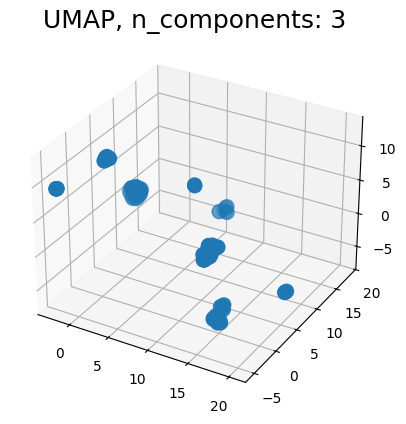

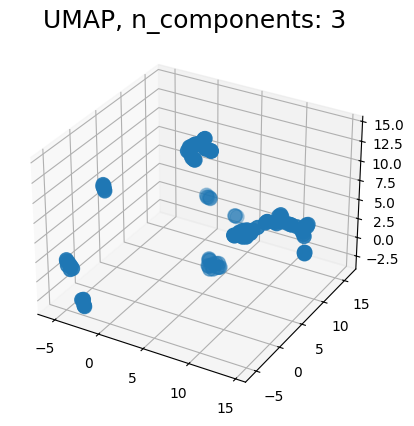

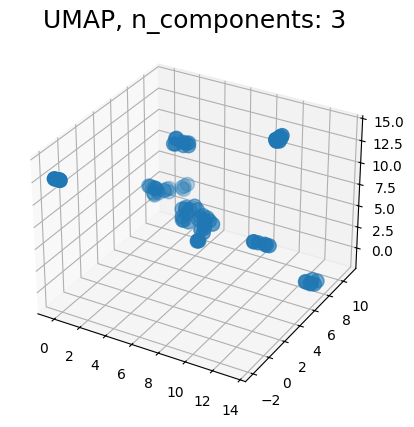

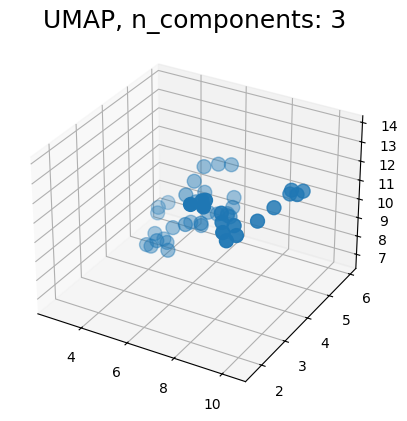

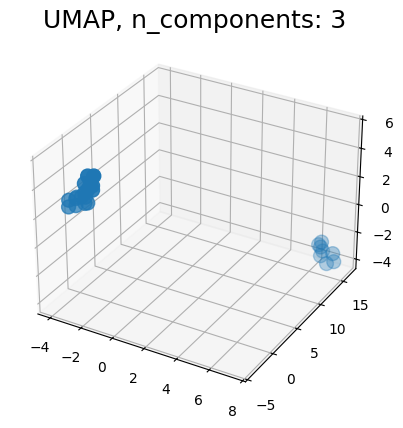

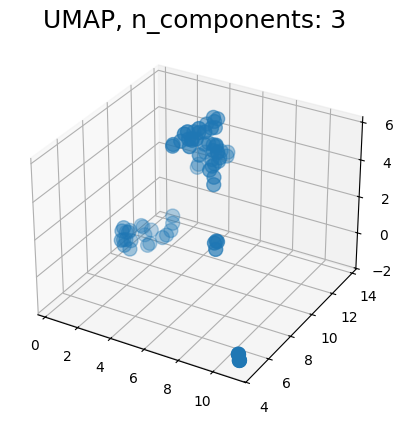

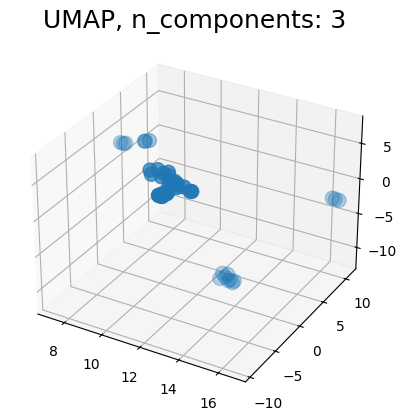

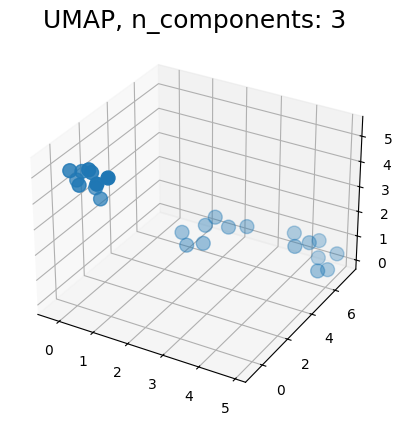

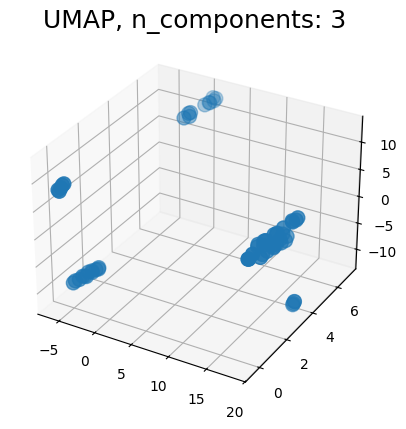

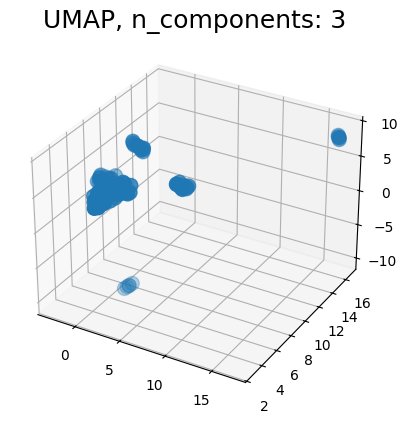

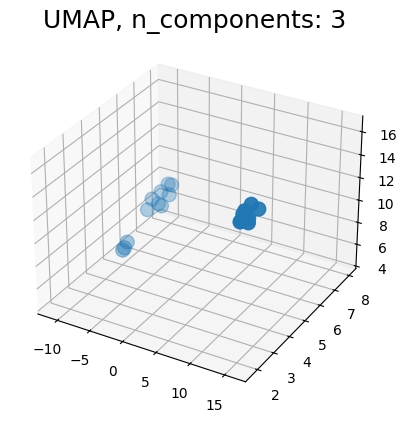

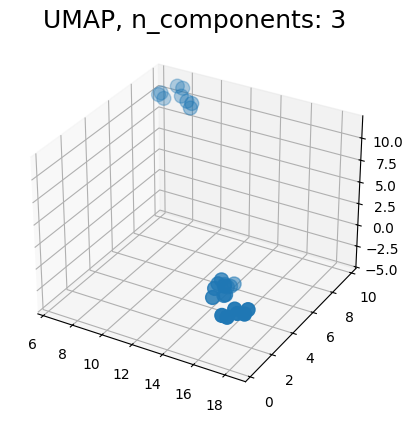

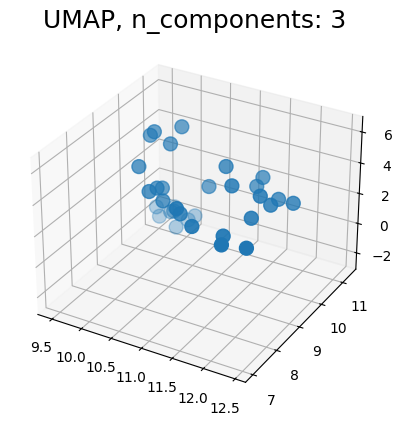

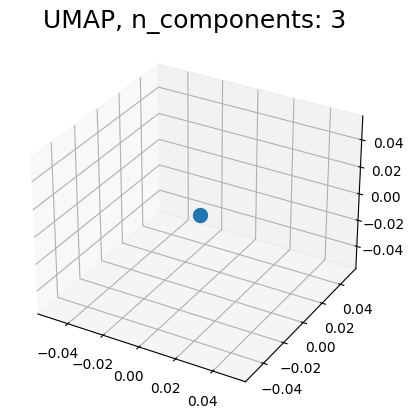

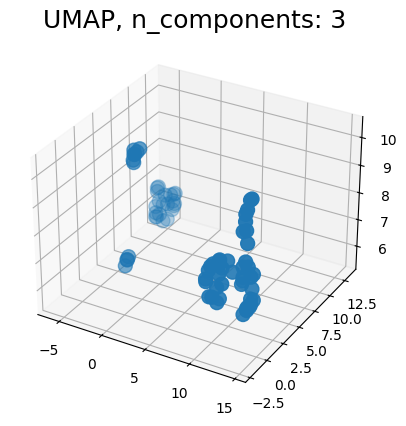

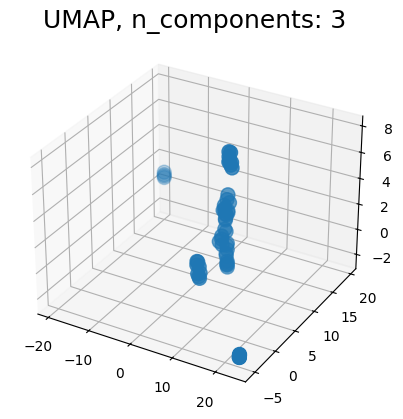

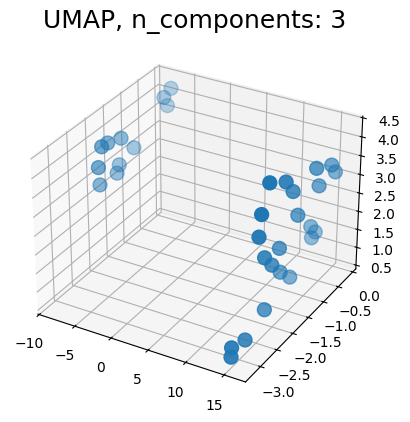

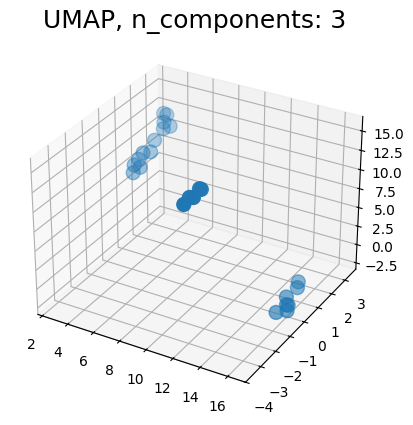

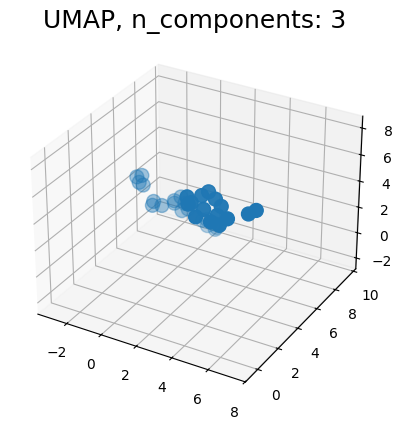

In [ ]:
if __name__ == "__main__":

    dfs = main_FinSim(dfs)

In [ ]:
dfs[17].show(50)

25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

+---+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+--------------------+--------------------+-------------------+--------------------+--------------------+----------------+--------------------+------------------+
|idx|      date|             content|ticker|               title|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|period_start|period_end|biweekly_period|next_announcement|biweekly_index|      polarity_title|    polarity_content| subjectivity_title|subjectivity_content|  finbert_embeddings|ollama_sentiment|                 FPI|     Financing_sim|
+---+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------

25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

In [ ]:
for i, df in enumerate(dfs):
    df.write.mode("overwrite").parquet(f"./Intermediate_data/df_{i}.parquet")

25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

# Basetable 

In [ ]:
def safe_expr(expr):
    try:
        return expr
    except Exception:
        return F.lit(np.nan)

# -------------------------------------------------------
# Main aggregation function
# -------------------------------------------------------

def aggregate_sentiment(df):

    agg_sent = (
        df
        .groupBy(
            [F.col("biweekly_period"),
            F.col("biweekly_index")]
        )
        .agg(
            # DEPENDENT VARIABLE
            F.mode('next_announcement').alias("next_announcement"),

            # GENERAL ARTICLE FEATURES 
            F.count("*").alias("n_artices"),
            F.avg('num_words_title').alias("avg_num_words_title"), 
            F.avg('num_words_content').alias("avg_num_words_content"), 

            # POLARITY AND SUBJECTIVITY FEATURES
            F.avg("polarity_title").alias("avg_polarity_title"),
            F.avg("polarity_content").alias("avg_polarity_content"),
            F.avg("subjectivity_title").alias("avg_subjectivity_title"),
            F.avg("subjectivity_content").alias("avg_subjectivity_content"),

            # OLLAMA SENTIMENT FEATURES 
            safe_expr(F.avg("ollama_sentiment").alias("avg_ollama")),
            safe_expr(F.stddev_pop("ollama_sentiment").alias("std_ollama")),
            safe_expr(F.min("ollama_sentiment").alias("min_ollama")),
            safe_expr(F.max("ollama_sentiment").alias("max_ollama")),

            # EMBEDDING FEATURES ...
            F.collect_list("finbert_arr").alias("finbert_arr_list")
        )
    )

    agg_sent = (
        agg_sent
        .withColumn("avg_finbert_array", mean_array_udf("finbert_arr_list"))
        .drop("finbert_arr_list")
    )

    agg_sent = agg_sent.withColumn(
        "avg_finbert_vec",
        to_vec_udf("avg_finbert_array")
    )
    
    return agg_sent


def main_basetable(dfs_list): 

    dfs_basetable = []

    for df in dfs_list:
        basetable = aggregate_sentiment(df).cache()

        dfs_basetable.append(basetable)

    return dfs_basetable
    